# Diabetes risk model

This notebook trains the model used in Glucorisk using 12 health factors from the 2023 CDC BRFSS survey. The target combines self-reported diabetes and prediabetes.

The model gives a screening score, not a diagnosis.

Data: https://www.cdc.gov/brfss/annual_data/annual_2023.html

## Setup

Install SHAP for feature analysis, skl2onnx for export, and ONNX Runtime to check the exported model.

In [1]:
!pip install shap skl2onnx onnxruntime --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.2/317.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 44.6 MB/s eta 0:00:00


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.pipeline import Pipeline
from sklearn.calibration import _sigmoid_calibration, calibration_curve
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, AdaBoostClassifier,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV

import shap

## Load the data

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
xpt_path = "/content/drive/MyDrive/diabetes_prediction_app/LLCP2023.XPT"

if not os.path.exists(xpt_path):
    raise FileNotFoundError(f"Couldn't find {xpt_path}")

print("Found file:", xpt_path)

Found file: /content/drive/MyDrive/diabetes_prediction_app/LLCP2023.XPT


In [5]:
# Load the CDC SAS transport file.
df_raw = pd.read_sas(xpt_path, format="xport", encoding="latin-1")
print(f"Loaded {len(df_raw):,} rows, {len(df_raw.columns)} columns")

Loaded 433,323 rows, 350 columns


## Clean the data and select features

DIABETE4 records whether a respondent was told they had diabetes. Diabetes and prediabetes responses form the positive class; no diabetes forms the negative class. Gestational-only diabetes is excluded.

The 12 features use health information available without a blood test. Print the column names below to check the survey variables.

In [6]:
pd.set_option('display.max_rows', None)
for col in sorted(df_raw.columns.tolist()):
    print(col)

ACEADNED
ACEADSAF
ACEDEPRS
ACEDIVRC
ACEDRINK
ACEDRUGS
ACEHURT1
ACEHVSEX
ACEPRISN
ACEPUNCH
ACESWEAR
ACETOUCH
ACETTHEM
ACTIN13_
ACTIN23_
ADDEPEV3
ALCDAY4
ARTHDIS2
ARTHEDU
ARTHEXER
ASPIRIN
ASTHMA3
ASTHNOW
AVEDRNK3
BIRTHSEX
BLDSTFIT
BLIND
BPHIGH6
BPMEDS1
CADULT1
CAGEG
CAREGIV1
CASTHDX2
CASTHNO2
CCLGHOUS
CDDISCU1
CDHOUS1
CDSOCIA1
CDWORRY
CELLFON5
CELLSEX2
CELPHON1
CELSXBRT
CERVSCRN
CHCCOPD3
CHCKDNY2
CHCOCNC1
CHCSCNC1
CHECKUP1
CHILDREN
CHKHEMO3
CHOLCHK3
CHOLMED3
CIMEMLO1
CNCRAGE
CNCRDIFF
CNCRTYP2
COLGHOUS
COLNCNCR
COLNSIGM
COLNTES1
COVACGE1
COVIDACT
COVIDNU2
COVIDPO1
COVIDSM1
COVIDVA1
CPDEMO1C
CRGVALZD
CRGVEXPT
CRGVHOU1
CRGVHRS1
CRGVLNG1
CRGVPER1
CRGVPRB3
CRGVREL4
CRVCLCNC
CRVCLHPV
CRVCLPAP
CSRVCLIN
CSRVCTL2
CSRVDEIN
CSRVDOC1
CSRVINSR
CSRVINST
CSRVPAIN
CSRVRTRN
CSRVSUM
CSRVTRT3
CSTATE1
CTELENM1
CTELNUM1
CVDCRHD4
CVDINFR4
CVDSTRK3
DEAF
DECIDE
DIABAGE4
DIABEDU1
DIABETE4
DIABEYE1
DIABTYPE
DIFFALON
DIFFDRES
DIFFWALK
DISPCODE
DRNK3GE5
DRNKANY6
DRNKDRI2
DROCDY4_
ECIGNOW2
EDUCA
EMPLOY1
EMTSUPRT
EXE

In [7]:
# Encode the target and health-history variables.
df = df_raw[df_raw["DIABETE4"].isin([1, 3, 4])].copy()
df["at_risk"] = df["DIABETE4"].map({1: 1, 4: 1, 3: 0})

# Combine high and borderline high blood pressure.
df = df[df["BPHIGH6"].isin([1, 3, 4])].copy()
df["high_bp"] = df["BPHIGH6"].map({1: 1, 4: 1, 3: 0})

df = df[df["TOLDHI3"].isin([1, 2])].copy()
df["high_chol"] = df["TOLDHI3"].map({1: 1, 2: 0})

df = df[df["DIFFWALK"].isin([1, 2])].copy()
df["diff_walk"] = df["DIFFWALK"].map({1: 1, 2: 0})

# Keep the three cardiovascular histories as separate inputs.
df = df[df["CVDSTRK3"].isin([1, 2])].copy()
df["stroke_history"] = df["CVDSTRK3"].map({1: 1, 2: 0})

df = df[df["CVDCRHD4"].isin([1, 2])].copy()
df["angina_chd_history"] = df["CVDCRHD4"].map({1: 1, 2: 0})

df = df[df["CVDINFR4"].isin([1, 2])].copy()
df["heart_attack_history"] = df["CVDINFR4"].map({1: 1, 2: 0})

FEATURES = [
    "GENHLTH", "_AGEG5YR", "SEXVAR", "_BMI5", "EXERANY2",
    "high_bp", "high_chol", "SMOKE100", "diff_walk",
    "stroke_history", "angina_chd_history", "heart_attack_history",
]

missing_cols = [c for c in ["GENHLTH", "_AGEG5YR", "SEXVAR", "_BMI5", "EXERANY2", "SMOKE100"] if c not in df.columns]
if missing_cols:
    print("WARNING - columns not found, check this year's codebook:", missing_cols)
else:
    print("All expected columns found.")

model_df = df[FEATURES + ["at_risk"]].copy()

for col in ["GENHLTH", "EXERANY2", "SMOKE100"]:
    model_df = model_df[~model_df[col].isin([7, 9])]
model_df = model_df[model_df["_BMI5"].notna()]

# Remove any remaining rows with missing features.
model_df = model_df.dropna(subset=FEATURES)

print(f"{len(model_df):,} rows remain after cleaning")
print(model_df["at_risk"].value_counts(normalize=True))

All expected columns found.
324,787 rows remain after cleaning
at_risk
0    0.824273
1    0.175727
Name: proportion, dtype: float64


## Split the data

Use 80% for training, 10% for validation, and 10% for testing. Stratify by the target so the splits have similar proportions of positive cases. Keep seed 42.

In [8]:
train_df, temp_df = train_test_split(
    model_df, test_size=0.20, random_state=42, stratify=model_df["at_risk"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["at_risk"]
)

print(f"Train: {len(train_df):,} rows")
print(f"Validation: {len(val_df):,} rows")
print(f"Test: {len(test_df):,} rows")

Train: 259,829 rows
Validation: 32,479 rows
Test: 32,479 rows


## Class weights

About 18% of the cleaned responses are positive. Give the two classes equal total weight when the classifier supports sample weights.

In [9]:
X_train, y_train = train_df[FEATURES], train_df["at_risk"]
X_val, y_val = val_df[FEATURES], val_df["at_risk"]
X_test, y_test = test_df[FEATURES], test_df["at_risk"]

sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## Compare models

Train each classifier and select the one with the highest validation AUC.

In [10]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, max_depth=8, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15),  # Fit without weights if unsupported.
    "Gaussian Naive Bayes": GaussianNB(),
    "Linear SVM": CalibratedClassifierCV(LinearSVC(max_iter=5000, random_state=42)),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42),  # Fit without weights if unsupported.
}

val_scores = {}
for name, model in candidates.items():
    try:
        model.fit(X_train_scaled, y_train, sample_weight=sample_weights)
    except TypeError:
        model.fit(X_train_scaled, y_train)

    val_probs = model.predict_proba(X_val_scaled)[:, 1]
    val_scores[name] = roc_auc_score(y_val, val_probs)
    print(f"{name:.<25} ROC-AUC = {val_scores[name]:.3f}")

best_name = max(val_scores, key=val_scores.get)
best_model = candidates[best_name]
print(f"\nBest model: {best_name} (ROC-AUC = {val_scores[best_name]:.3f})")

Logistic Regression...... ROC-AUC = 0.789
Decision Tree............ ROC-AUC = 0.787
Random Forest............ ROC-AUC = 0.793
Extra Trees.............. ROC-AUC = 0.779
Gradient Boosting........ ROC-AUC = 0.797
AdaBoost................. ROC-AUC = 0.792
K-Nearest Neighbors...... ROC-AUC = 0.757
Gaussian Naive Bayes..... ROC-AUC = 0.767
Linear SVM............... ROC-AUC = 0.788
Neural Network (MLP)..... ROC-AUC = 0.796

Best model: Gradient Boosting (ROC-AUC = 0.797)


## Calibrate probabilities

Fit a sigmoid correction using validation predictions so the scores better match the observed positive rates.

In [11]:
val_raw_probs = best_model.predict_proba(X_val_scaled)[:, 1]
calibration_a, calibration_b = _sigmoid_calibration(val_raw_probs, y_val)
print(f"Calibration params: a={calibration_a:.6f}, b={calibration_b:.6f}")

def calibrate(raw_probs):
    return 1 / (1 + np.exp(calibration_a * raw_probs + calibration_b))

val_calibrated = calibrate(val_raw_probs)

print("\nBefore calibration:")
for actual, predicted in zip(*calibration_curve(y_val, val_raw_probs, n_bins=8, strategy="quantile")):
    print(f"  predicted ~{predicted:.2f} -> actually at risk {actual:.2f}")

print("\nAfter calibration:")
for actual, predicted in zip(*calibration_curve(y_val, val_calibrated, n_bins=8, strategy="quantile")):
    print(f"  predicted ~{predicted:.2f} -> actually at risk {actual:.2f}")

Calibration params: a=-4.842513, b=3.995174

Before calibration:
  predicted ~0.07 -> actually at risk 0.01
  predicted ~0.13 -> actually at risk 0.03
  predicted ~0.22 -> actually at risk 0.06
  predicted ~0.34 -> actually at risk 0.10
  predicted ~0.46 -> actually at risk 0.15
  predicted ~0.58 -> actually at risk 0.24
  predicted ~0.69 -> actually at risk 0.33
  predicted ~0.82 -> actually at risk 0.49

After calibration:
  predicted ~0.02 -> actually at risk 0.01
  predicted ~0.03 -> actually at risk 0.03
  predicted ~0.05 -> actually at risk 0.06
  predicted ~0.09 -> actually at risk 0.10
  predicted ~0.14 -> actually at risk 0.15
  predicted ~0.23 -> actually at risk 0.24
  predicted ~0.34 -> actually at risk 0.33
  predicted ~0.49 -> actually at risk 0.49


## Choose the cutoff

Choose the highest cutoff that gives recall above 96% on the validation set. This keeps the number of flagged respondents as low as possible while meeting that target. The selection uses the exact scores rather than a rounded grid.

A lower cutoff flags more people and usually reduces precision. Test recall is measured separately and may fall below the validation target. AUC does not change when only the cutoff changes.

In [21]:
TARGET_RECALL = 0.96

def select_recall_threshold(labels, scores, target_recall=0.95):
    labels = np.asarray(labels)
    scores = np.asarray(scores, dtype=float)
    if labels.ndim != 1 or scores.ndim != 1 or labels.shape != scores.shape:
        raise ValueError("Labels and scores must be matching one-dimensional arrays.")
    if not np.all(np.isin(labels, [0, 1])):
        raise ValueError("Labels must be 0 or 1.")
    if not np.all(np.isfinite(scores)) or np.any((scores < 0) | (scores > 1)):
        raise ValueError("Scores must be finite probabilities between 0 and 1.")
    if not 0 < target_recall < 1:
        raise ValueError("The recall target must be between 0 and 1.")

    positive_scores = np.sort(scores[labels == 1])[::-1]
    if len(positive_scores) == 0:
        raise ValueError("Recall selection requires positive validation cases.")

    # Catch enough positives to exceed the target; include tied scores.
    required_tp = int(np.floor(target_recall * len(positive_scores))) + 1
    return float(positive_scores[required_tp - 1])

threshold = select_recall_threshold(y_val, val_calibrated, TARGET_RECALL)
val_preds = (val_calibrated >= threshold).astype(int)
val_tn, val_fp, val_fn, val_tp = confusion_matrix(y_val, val_preds, labels=[0, 1]).ravel()
val_recall = recall_score(y_val, val_preds)
val_precision = precision_score(y_val, val_preds, zero_division=0)
val_specificity = val_tn / (val_tn + val_fp) if val_tn + val_fp else float("nan")
assert val_recall > TARGET_RECALL

print(f"Chosen threshold: {threshold:.17g}")
print(f"Validation recall:      {val_recall:.4f}")
print(f"Validation precision:   {val_precision:.4f}")
print(f"Validation specificity: {val_specificity:.4f}")
print(f"Validation flagged:     {val_preds.mean():.1%}")
print(f"Validation false negatives: {val_fn}")

Chosen threshold: 0.047328623676877533
Validation recall:      0.9601
Validation precision:   0.2374
Validation specificity: 0.3423
Validation flagged:     71.1%
Validation false negatives: 228


## Test results

Apply the fixed cutoff to the test set. Report recall, precision, specificity, and the number of respondents flagged, along with AUC and accuracy.

If earlier test results helped you choose the recall target, these results are exploratory. Use a new test cohort for a fresh evaluation.

=== Gradient Boosting at threshold 0.047328623676877533 ===
AUC:        0.796
Recall:     0.9585
Precision:  0.2366
Specificity: 0.3408
Accuracy:   0.4493
Flagged:    23,118 of 32,479 (71.2%)
False negatives: 237 of 5,707 positive cases
False positives: 17,648 of 26,772 negative cases

Confusion matrix:
[[ 9124 17648]
 [  237  5470]]


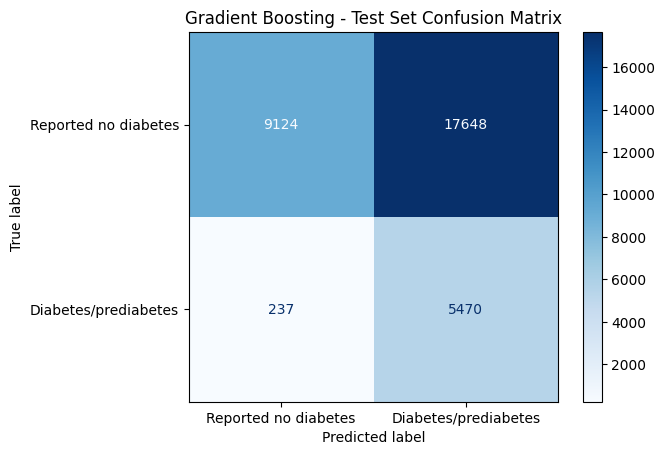

In [22]:
test_raw_probs = best_model.predict_proba(X_test_scaled)[:, 1]
test_calibrated = calibrate(test_raw_probs)
test_preds = (test_calibrated >= threshold).astype(int)

auc = roc_auc_score(y_test, test_calibrated)
precision = precision_score(y_test, test_preds, zero_division=0)
recall = recall_score(y_test, test_preds)
accuracy = accuracy_score(y_test, test_preds)

cm = confusion_matrix(y_test, test_preds, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp) if tn + fp else float("nan")
flagged_fraction = float(test_preds.mean())

print(f"=== {best_name} at threshold {threshold:.17g} ===")
print(f"AUC:        {auc:.3f}")
print(f"Recall:     {recall:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Specificity:{specificity: .4f}")
print(f"Accuracy:   {accuracy:.4f}")
print(f"Flagged:    {test_preds.sum():,} of {len(test_preds):,} ({flagged_fraction:.1%})")
print(f"False negatives: {fn:,} of {tp + fn:,} positive cases")
print(f"False positives: {fp:,} of {tn + fp:,} negative cases")


print("\nConfusion matrix:")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Reported no diabetes", "Diabetes/prediabetes"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"{best_name} - Test Set Confusion Matrix")
plt.show()

## Feature importance

Use SHAP to examine which features contribute most to the model's predictions. This analysis is separate from the app's recommendation rules.

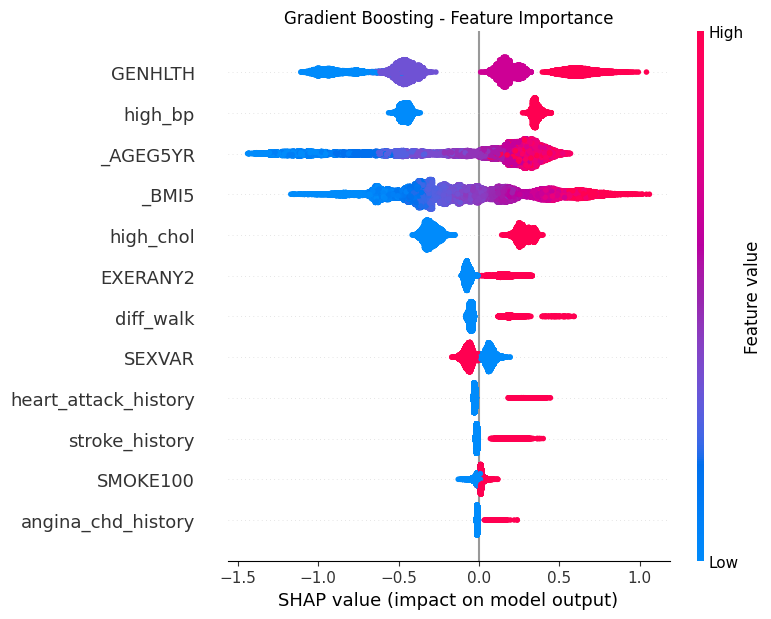

In [23]:
X_shap = X_test_scaled
try:
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_test_scaled)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif np.array(shap_values).ndim == 3:
        shap_values = shap_values[:, :, 1]
except Exception as e:
    print(f"TreeExplainer didn't work ({e}), using the slower general explainer instead")
    background = shap.sample(X_test_scaled, 100, random_state=42)
    sample = shap.sample(X_test_scaled, 300, random_state=42)
    explainer = shap.Explainer(best_model.predict_proba, background)
    shap_values = explainer(sample).values[:, :, 1]
    X_shap = sample

shap.summary_plot(shap_values, X_shap, feature_names=FEATURES, show=False)
plt.title(f"{best_name} - Feature Importance")
plt.tight_layout()
plt.show()

In [24]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)
ranking = sorted(zip(FEATURES, mean_abs_shap.tolist()), key=lambda x: -x[1])

print("export const FEATURE_IMPORTANCE = [")
for feature, importance in ranking:
    print(f'  {{ feature: "{feature}", importance: {importance:.4f} }},')
print("];")

export const FEATURE_IMPORTANCE = [
  { feature: "GENHLTH", importance: 0.4608 },
  { feature: "high_bp", importance: 0.4122 },
  { feature: "_AGEG5YR", importance: 0.4013 },
  { feature: "_BMI5", importance: 0.3504 },
  { feature: "high_chol", importance: 0.2922 },
  { feature: "EXERANY2", importance: 0.0933 },
  { feature: "diff_walk", importance: 0.0749 },
  { feature: "SEXVAR", importance: 0.0672 },
  { feature: "heart_attack_history", importance: 0.0417 },
  { feature: "stroke_history", importance: 0.0215 },
  { feature: "SMOKE100", importance: 0.0203 },
  { feature: "angina_chd_history", importance: 0.0169 },
];


## Save the model and app settings

Save the fitted classifier and scaler. Export the cutoff and calibration values at full precision so the app uses the same settings as this run.

In [25]:
from google.colab import files
import json

joblib.dump(best_model, "diabetes_risk_model.joblib")
joblib.dump(scaler, "diabetes_risk_scaler.joblib")

app_settings = {
    "calibration_a": float(calibration_a),
    "calibration_b": float(calibration_b),
    "threshold": float(threshold),
    "target_validation_recall": TARGET_RECALL,
    "validation_recall": float(val_recall),
    "test_auc": float(auc),
    "test_recall": float(recall),
    "test_precision": float(precision),
    "test_specificity": float(specificity),
    "test_accuracy": float(accuracy),
    "test_flagged_fraction": flagged_fraction,
    "test_confusion_matrix": cm.tolist(),
    "features": FEATURES,
}
with open("app_settings.json", "w") as f:
    json.dump(app_settings, f, indent=2)

# Use full precision so the app does not round the chosen cutoff upward.
app_constants = (
    f"export const CALIBRATION_A = {float(calibration_a)!r};\n"
    f"export const CALIBRATION_B = {float(calibration_b)!r};\n"
    f"export const RECOMMENDED_THRESHOLD = {float(threshold)!r};\n"
)
with open("app_constants.js", "w") as f:
    f.write(app_constants)
print(app_constants)

with open("model_info.txt", "w") as f:
    f.write(f"Model: {best_name}\n")
    f.write(f"Threshold: {threshold:.17g}\n")
    f.write(f"Target validation recall: >{TARGET_RECALL}\n")
    f.write(f"Validation recall: {val_recall:.6f}\n")
    f.write(f"Validation AUC: {val_scores[best_name]:.6f}\n")
    f.write(f"Test AUC: {auc:.6f}\n")
    f.write(f"Test recall: {recall:.6f}\n")
    f.write(f"Test precision: {precision:.6f}\n")
    f.write(f"Test specificity: {specificity:.6f}\n")
    f.write(f"Test accuracy: {accuracy:.6f}\n")
    f.write(f"Test flagged fraction: {flagged_fraction:.6f}\n")
    f.write(f"Test false negatives: {fn}\n")
    f.write(f"Test false positives: {fp}\n")
    f.write(f"Features: {FEATURES}\n")

for filename in ["diabetes_risk_model.joblib", "diabetes_risk_scaler.joblib",
                 "model_info.txt", "app_settings.json", "app_constants.js"]:
    files.download(filename)
print("Saved and downloaded.")

export const CALIBRATION_A = -4.842512688506816;
export const CALIBRATION_B = 3.9951738125617853;
export const RECOMMENDED_THRESHOLD = 0.04732862367687753;



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved and downloaded.


## Export to ONNX

Bundle the scaler and classifier into one pipeline for the phone to run. Set zipmap=False so the probabilities are returned as an array. The app applies calibration and the cutoff separately.

In [26]:
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType

export_pipeline = Pipeline([
    ("scaler", scaler),
    ("model", best_model),
])

initial_type = [("float_input", FloatTensorType([None, len(FEATURES)]))]
options = {id(best_model): {"zipmap": False}}
onnx_model = convert_sklearn(export_pipeline, initial_types=initial_type, target_opset=15, options=options)

with open("diabetes_risk_model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

print(f"Saved diabetes_risk_model.onnx ({len(onnx_model.SerializeToString()):,} bytes)")

Saved diabetes_risk_model.onnx (55,893 bytes)


## Check the export

Compare scikit-learn and ONNX predictions on five test rows.

In [27]:
import onnxruntime as rt

session = rt.InferenceSession("diabetes_risk_model.onnx", providers=["CPUExecutionProvider"])
input_name = session.get_inputs()[0].name

check_rows_df = X_test.iloc[:5]
check_rows_np = check_rows_df.to_numpy().astype(np.float32)

sklearn_probs = export_pipeline.predict_proba(check_rows_df)[:, 1]

# Extract the positive-class probability.
onnx_labels, onnx_probs_array = session.run(None, {input_name: check_rows_np})
onnx_probs = onnx_probs_array[:, 1]

print("scikit-learn:", np.round(sklearn_probs, 4))
print("ONNX:        ", np.round(onnx_probs, 4))
print("Match:", np.allclose(sklearn_probs, onnx_probs, atol=1e-4))

files.download("diabetes_risk_model.onnx")

scikit-learn: [0.5444 0.221  0.2787 0.7142 0.7785]
ONNX:         [0.5444 0.221  0.2787 0.7142 0.7785]
Match: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Use in the app

Copy the three lines from app_constants.js into src/constants.js, replacing CALIBRATION_A, CALIBRATION_B, and RECOMMENDED_THRESHOLD. Keep all printed digits for the cutoff.

If you reran training, also replace assets/model/diabetes_risk_model.onnx with this run's export. Update the app's performance table and README with the new test results. Changing this notebook alone does not change the installed app.